# Module 09, Part 4: Policy gradients and Proximal Policy Optimization

This notebook is the runnable companion to Part 4 of the Module 09 learning content. It checks, with code:

1. That the REINFORCE estimate of the policy gradient agrees with the exact gradient on the grid from Part 1, and what a baseline does to its noise.
2. How REINFORCE, PPO and the DQN from Part 3 compare on CartPole under the same interaction budget of 30,000 steps, with three seeds each.
3. What the clipped PPO objective looks like, and what happens to training when the clipping is removed and each batch of data is reused with large steps.

The policy-gradient methods here learn a policy directly: a network that outputs the probability of each action. Part 3 learned a value and acted greedily on it.

In [1]:
import time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
torch.set_num_threads(1)
INK, BODY, MUTED = "#14161B", "#4E5563", "#7C838C"
NAVY, GREEN, AMBER, KEY, RULE = "#1C3D6E", "#0E6B57", "#8A6A18", "#7A2E8A", "#D9DCE2"

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": RULE, "axes.labelcolor": BODY, "xtick.color": BODY, "ytick.color": BODY,
    "axes.grid": True, "grid.color": RULE, "font.size": 10,
})

In [2]:
import numpy as np

ACTIONS = ["up", "right", "down", "left"]
MOVES = [(-1, 0), (0, 1), (1, 0), (0, -1)]


class GridMDP:
    """Rows 0 to 3, columns 0 to 3. The goal (+1) is the top-right corner, the pit (-1) is the cell below it.
    Both are terminal. A wall cell sits at (1, 1). Every other step costs `step_cost`.
    With probability `slip` the agent moves at a right angle to the chosen direction (half each way)."""
    def __init__(self, slip=0.2, step_cost=0.0, gamma=0.9):
        self.n_rows = self.n_cols = 4
        self.goal, self.pit, self.wall = (0, 3), (1, 3), (1, 1)
        self.slip, self.step_cost, self.gamma = slip, step_cost, gamma
        self.cells = [(r, c) for r in range(4) for c in range(4) if (r, c) != self.wall]
        self.idx = {cell: i for i, cell in enumerate(self.cells)}
        self.nS, self.nA = len(self.cells), 4
        self.terminal = np.array([c in (self.goal, self.pit) for c in self.cells])
        self.P = np.zeros((self.nS, self.nA, self.nS))
        self.R = np.zeros((self.nS, self.nA))
        for cell in self.cells:
            s = self.idx[cell]
            if self.terminal[s]:
                self.P[s, :, s] = 1.0        # absorbing, no further reward
                continue
            for a in range(self.nA):
                for a2, pr in ((a, 1 - slip), ((a + 1) % 4, slip / 2), ((a - 1) % 4, slip / 2)):
                    nxt = self._move(cell, a2)
                    self.P[s, a, self.idx[nxt]] += pr
                    reward = 1.0 if nxt == self.goal else -1.0 if nxt == self.pit else step_cost
                    self.R[s, a] += pr * reward

    def _move(self, cell, a):
        r, c = cell[0] + MOVES[a][0], cell[1] + MOVES[a][1]
        if not (0 <= r < 4 and 0 <= c < 4) or (r, c) == self.wall:
            return cell
        return (r, c)

    def sample_step(self, s, a, rng):
        s2 = rng.choice(self.nS, p=self.P[s, a])
        return s2, self.R[s, a]


def evaluate_policy(mdp, pi):
    """Solve the Bellman expectation equations v = r_pi + gamma P_pi v exactly. pi has shape (nS, nA)."""
    P_pi = np.einsum("sa,sat->st", pi, mdp.P)
    r_pi = np.einsum("sa,sa->s", pi, mdp.R)
    return np.linalg.solve(np.eye(mdp.nS) - mdp.gamma * P_pi, r_pi)


def q_from_v(mdp, v):
    return mdp.R + mdp.gamma * mdp.P @ v


def value_iteration(mdp, tol=1e-10, max_iter=10000):
    v = np.zeros(mdp.nS)
    for k in range(1, max_iter + 1):
        v_new = q_from_v(mdp, v).max(1)
        done = np.abs(v_new - v).max() < tol
        v = v_new
        if done:
            break
    return v, k


def greedy_policy(q):
    pi = np.zeros_like(q)
    pi[np.arange(len(q)), q.argmax(1)] = 1.0
    return pi


def discounted_return(rewards, gamma):
    g = 0.0
    for r in reversed(rewards):
        g = r + gamma * g
    return g


def rollout_return(mdp, pi, s0, rng, max_steps=200):
    s, rewards = s0, []
    for _ in range(max_steps):
        if mdp.terminal[s]:
            break
        a = rng.choice(mdp.nA, p=pi[s])
        s, r = mdp.sample_step(s, a, rng)
        rewards.append(r)
    return discounted_return(rewards, mdp.gamma), len(rewards)


def q_learning(mdp, steps=20000, eps=0.1, alpha=0.1, seed=0, start=None, max_ep_len=100, optimistic=0.0):
    """Tabular Q-learning with an epsilon-greedy behaviour policy. Returns the Q table and how many
    episodes reached the goal. Every episode starts in `start` (default: the bottom-left corner)."""
    rng = np.random.default_rng(seed)
    start = mdp.idx[(3, 0)] if start is None else start
    Q = np.full((mdp.nS, mdp.nA), optimistic)
    Q[mdp.terminal] = 0.0
    s, ep_len, goals = start, 0, 0
    goal_state = mdp.idx[mdp.goal]
    for _ in range(steps):
        a = int(rng.integers(mdp.nA)) if rng.random() < eps else int(np.argmax(Q[s] + 1e-9 * rng.random(mdp.nA)))
        s2, r = mdp.sample_step(s, a, rng)
        Q[s, a] += alpha * (r + mdp.gamma * Q[s2].max() - Q[s, a])
        ep_len += 1
        if mdp.terminal[s2] or ep_len >= max_ep_len:
            goals += int(s2 == goal_state)
            s, ep_len = start, 0
        else:
            s = s2
    return Q, goals


def softmax_policy(theta):
    import torch
    return torch.softmax(theta, dim=1)


def exact_objective(mdp, theta, s0):
    """J(theta) = v_pi(s0) for a softmax policy with logits theta (nS by nA), computed exactly and differentiably."""
    import torch
    pi = torch.softmax(theta, dim=1)
    P = torch.as_tensor(mdp.P, dtype=torch.float64); R = torch.as_tensor(mdp.R, dtype=torch.float64)
    P_pi = torch.einsum("sa,sat->st", pi, P); r_pi = (pi * R).sum(1)
    v = torch.linalg.solve(torch.eye(mdp.nS, dtype=torch.float64) - mdp.gamma * P_pi, r_pi)
    return v[s0]


def reinforce_gradient_estimate(mdp, theta, s0, n_episodes, rng, baseline=False, max_steps=100):
    """Monte Carlo policy-gradient estimate: average over episodes of sum_t gamma^t grad log pi(a_t|s_t) (G_t - b).
    With baseline=True, b is the exact state value v_pi(s_t), which depends on the state and not on the action."""
    pi = np.exp(theta - theta.max(1, keepdims=True)); pi /= pi.sum(1, keepdims=True)
    v = evaluate_policy(mdp, pi) if baseline else np.zeros(mdp.nS)
    grads = np.zeros((n_episodes,) + theta.shape)
    for e in range(n_episodes):
        s, traj = s0, []
        for _ in range(max_steps):
            if mdp.terminal[s]:
                break
            a = rng.choice(mdp.nA, p=pi[s]); s2, r = mdp.sample_step(s, a, rng)
            traj.append((s, a, r)); s = s2
        G = 0.0
        for t in reversed(range(len(traj))):
            s_t, a_t, r_t = traj[t]
            G = r_t + mdp.gamma * G
            g = -pi[s_t].copy(); g[a_t] += 1.0          # gradient of log softmax with respect to the logits
            grads[e, s_t] += mdp.gamma ** t * g * (G - v[s_t])
    return grads

In [3]:
import math
import numpy as np


class CartPole:
    """State: cart position, cart velocity, pole angle, pole angular velocity.
    Actions: 0 pushes the cart left, 1 pushes it right. Reward is +1 for every step the pole stays up.
    An episode ends when the pole tilts past 12 degrees, the cart leaves the track, or max_steps is reached."""
    n_actions = 2
    obs_dim = 4

    def __init__(self, seed=0, max_steps=200):
        self.rng = np.random.default_rng(seed)
        self.max_steps = max_steps
        self.g, self.mc, self.mp, self.l, self.force, self.tau = 9.8, 1.0, 0.1, 0.5, 10.0, 0.02
        self.theta_lim = 12 * 2 * math.pi / 360
        self.x_lim = 2.4

    def reset(self):
        self.s = self.rng.uniform(-0.05, 0.05, size=4)
        self.t = 0
        return self.s.astype(np.float32)

    def step(self, a):
        x, xd, th, thd = self.s
        f = self.force if a == 1 else -self.force
        ct, st = math.cos(th), math.sin(th)
        tm = self.mc + self.mp
        pml = self.mp * self.l
        tmp = (f + pml * thd ** 2 * st) / tm
        tha = (self.g * st - ct * tmp) / (self.l * (4.0 / 3.0 - self.mp * ct ** 2 / tm))
        xa = tmp - pml * tha * ct / tm
        x, xd = x + self.tau * xd, xd + self.tau * xa
        th, thd = th + self.tau * thd, thd + self.tau * tha
        self.s = np.array([x, xd, th, thd])
        self.t += 1
        terminated = bool(abs(x) > self.x_lim or abs(th) > self.theta_lim)
        truncated = self.t >= self.max_steps
        return self.s.astype(np.float32), 1.0, terminated, truncated

In [4]:
import copy
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

from cartpole import CartPole


class QNet(nn.Module):
    def __init__(self, obs_dim=4, n_actions=2, hidden=64):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(obs_dim, hidden), nn.ReLU(), nn.Linear(hidden, hidden), nn.ReLU(),
                                 nn.Linear(hidden, n_actions))

    def forward(self, x):
        return self.net(x)


class Replay:
    """A ring buffer of transitions. With capacity equal to the batch size, a 'batch' is just the latest
    transitions in the order they happened, which is what learning without replay means."""
    def __init__(self, capacity, obs_dim=4):
        self.cap, self.n, self.i = capacity, 0, 0
        self.s = np.zeros((capacity, obs_dim), np.float32)
        self.a = np.zeros(capacity, np.int64)
        self.r = np.zeros(capacity, np.float32)
        self.s2 = np.zeros((capacity, obs_dim), np.float32)
        self.d = np.zeros(capacity, np.float32)

    def add(self, s, a, r, s2, d):
        self.s[self.i], self.a[self.i], self.r[self.i], self.s2[self.i], self.d[self.i] = s, a, r, s2, d
        self.i = (self.i + 1) % self.cap
        self.n = min(self.n + 1, self.cap)

    def sample(self, batch, rng):
        idx = rng.integers(0, self.n, size=batch)
        return [torch.as_tensor(x[idx]) for x in (self.s, self.a, self.r, self.s2, self.d)]


def train_dqn(seed=0, steps=20000, replay=True, target=True, gamma=0.99, lr=1e-3, batch=64,
              buffer=20000, warmup=500, target_every=250, eps_start=1.0, eps_end=0.05, eps_decay=8000,
              max_steps=200, log_every=None):
    """Returns the list of (env step at the end of the episode, episode return).
    replay=False: the buffer holds only the latest `batch` transitions, so every update uses consecutive,
        strongly correlated experience that is then thrown away.
    target=False: the bootstrap target is computed with the network that is being trained."""
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    env = CartPole(seed, max_steps)
    q = QNet()
    q_tgt = copy.deepcopy(q)
    opt = torch.optim.Adam(q.parameters(), lr=lr)
    buf = Replay(buffer if replay else batch)
    warm = warmup if replay else batch
    s = env.reset()
    ep_ret, episodes, q_log = 0.0, [], []
    for t in range(1, steps + 1):
        eps = max(eps_end, eps_start - (eps_start - eps_end) * t / eps_decay)
        if rng.random() < eps:
            a = int(rng.integers(2))
        else:
            with torch.no_grad():
                a = int(q(torch.as_tensor(s)[None]).argmax())
        s2, r, term, trunc = env.step(a)
        buf.add(s, a, r, s2, float(term))      # time-limit truncation is not a true terminal state
        ep_ret += r
        s = s2
        if term or trunc:
            episodes.append((t, ep_ret)); ep_ret = 0.0; s = env.reset()
        if t >= warm:
            bs, ba, br, bs2, bd = buf.sample(batch, rng) if replay else \
                [torch.as_tensor(x[:batch]) for x in (buf.s, buf.a, buf.r, buf.s2, buf.d)]
            if not replay and batch > 1:    # order the ring buffer so the batch really is the latest transitions
                order = [(buf.i + k) % buf.cap for k in range(buf.cap)]
                bs, ba, br, bs2, bd = [torch.as_tensor(x[order]) for x in (buf.s, buf.a, buf.r, buf.s2, buf.d)]
            with torch.no_grad():
                net = q_tgt if target else q
                y = br + gamma * (1 - bd) * net(bs2).max(1).values
            pred = q(bs).gather(1, ba[:, None])[:, 0]
            loss = F.smooth_l1_loss(pred, y)
            opt.zero_grad(); loss.backward()
            nn.utils.clip_grad_norm_(q.parameters(), 10.0)
            opt.step()
            if target and t % target_every == 0:
                q_tgt.load_state_dict(q.state_dict())
            if log_every and t % log_every == 0:
                with torch.no_grad():
                    q_log.append((t, float(q(bs).max(1).values.mean())))
    return (episodes, q_log) if log_every else episodes


def smooth_curve(episodes, steps, grid=500, window=2000):
    """Mean return of the episodes that ended in the last `window` steps, evaluated every `grid` steps."""
    ts = np.array([e[0] for e in episodes]); rs = np.array([e[1] for e in episodes])
    out = []
    for g in range(grid, steps + 1, grid):
        m = (ts > g - window) & (ts <= g)
        out.append(rs[m].mean() if m.any() else np.nan)
    return np.array(out)

In [5]:
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

from cartpole import CartPole


def mlp(i, o, hidden=64):
    return nn.Sequential(nn.Linear(i, hidden), nn.Tanh(), nn.Linear(hidden, hidden), nn.Tanh(), nn.Linear(hidden, o))


def returns_to_go(rewards, gamma):
    g, out = 0.0, np.zeros(len(rewards), np.float32)
    for i in reversed(range(len(rewards))):
        g = rewards[i] + gamma * g
        out[i] = g
    return out


def ppo_clip_objective(ratio, adv, eps=0.2):
    """The PPO surrogate for each sample: min(ratio * A, clip(ratio, 1 - eps, 1 + eps) * A). Higher is better."""
    return torch.minimum(ratio * adv, torch.clamp(ratio, 1 - eps, 1 + eps) * adv)


def train_reinforce(seed=0, steps=30000, baseline=True, gamma=0.99, lr=3e-3, episodes_per_update=8, max_steps=200):
    """Vanilla policy gradient. Each update uses whole episodes, so its signal is the return-to-go.
    With baseline=True the return is centred by a learned state-value function."""
    torch.manual_seed(seed)
    env = CartPole(seed, max_steps)
    pi, vf = mlp(4, 2), mlp(4, 1)
    opt = torch.optim.Adam(pi.parameters(), lr=lr)
    opt_v = torch.optim.Adam(vf.parameters(), lr=1e-2)
    t, log, grad_var = 0, [], []
    while t < steps:
        S, A, G, ep_ends = [], [], [], []
        for _ in range(episodes_per_update):
            s, obs, acts, rews = env.reset(), [], [], []
            while True:
                with torch.no_grad():
                    a = int(torch.distributions.Categorical(logits=pi(torch.as_tensor(s)[None])).sample())
                s2, r, term, trunc = env.step(a)
                obs.append(s); acts.append(a); rews.append(r); s = s2; t += 1
                if term or trunc:
                    break
            S += obs; A += acts; G += list(returns_to_go(rews, gamma))
            log.append((t, float(sum(rews))))
        S, A, G = torch.as_tensor(np.array(S)), torch.as_tensor(A), torch.as_tensor(np.array(G))
        if baseline:
            v = vf(S)[:, 0]
            adv = (G - v.detach())
            loss_v = F.mse_loss(v, G)
            opt_v.zero_grad(); loss_v.backward(); opt_v.step()
        else:
            adv = G
        adv = adv / (adv.std() + 1e-8)          # same rescaling in both cases; only the baseline differs
        logp = torch.distributions.Categorical(logits=pi(S)).log_prob(A)
        loss = -(logp * adv).mean()
        opt.zero_grad(); loss.backward(); opt.step()
    return log


def train_ppo(seed=0, steps=30000, rollout=1024, epochs=6, minibatch=128, clip=0.2, gamma=0.99, lam=0.95,
              lr=3e-4, max_steps=200, ent=0.0, use_clip=True):
    torch.manual_seed(seed)
    env = CartPole(seed, max_steps)
    pi, vf = mlp(4, 2), mlp(4, 1)
    opt = torch.optim.Adam(list(pi.parameters()) + list(vf.parameters()), lr=lr)
    s, ep_ret, log, t = env.reset(), 0.0, [], 0
    stats = []
    while t < steps:
        S = np.zeros((rollout, 4), np.float32); A = np.zeros(rollout, np.int64)
        R = np.zeros(rollout, np.float32); D = np.zeros(rollout, np.float32)
        NV = np.zeros(rollout, np.float32); LP = np.zeros(rollout, np.float32); V = np.zeros(rollout, np.float32)
        cut = np.zeros(rollout, np.float32)
        for i in range(rollout):
            st = torch.as_tensor(s)[None]
            with torch.no_grad():
                dist = torch.distributions.Categorical(logits=pi(st)); a = dist.sample()
                V[i] = vf(st)[0, 0]; LP[i] = dist.log_prob(a)
            s2, r, term, trunc = env.step(int(a))
            S[i], A[i], R[i] = s, int(a), r
            D[i] = float(term); cut[i] = float(term or trunc)
            with torch.no_grad():
                NV[i] = vf(torch.as_tensor(s2)[None])[0, 0]
            ep_ret += r; t += 1
            if term or trunc:
                log.append((t, ep_ret)); ep_ret = 0.0; s = env.reset()
            else:
                s = s2
        adv = np.zeros(rollout, np.float32); last = 0.0
        for i in reversed(range(rollout)):
            delta = R[i] + gamma * (1 - D[i]) * NV[i] - V[i]
            last = delta + gamma * lam * (1 - cut[i]) * last
            adv[i] = last
        ret = adv + V
        S_, A_, LP_, ADV, RET = map(torch.as_tensor, (S, A, LP, adv, ret))
        ADV = (ADV - ADV.mean()) / (ADV.std() + 1e-8)
        clipfrac = []
        for _ in range(epochs):
            perm = torch.randperm(rollout)
            for k in range(0, rollout, minibatch):
                idx = perm[k:k + minibatch]
                dist = torch.distributions.Categorical(logits=pi(S_[idx]))
                ratio = torch.exp(dist.log_prob(A_[idx]) - LP_[idx])
                surr = ppo_clip_objective(ratio, ADV[idx], clip) if use_clip else ratio * ADV[idx]
                loss = -surr.mean() + 0.5 * F.mse_loss(vf(S_[idx])[:, 0], RET[idx]) - ent * dist.entropy().mean()
                opt.zero_grad(); loss.backward()
                nn.utils.clip_grad_norm_(list(pi.parameters()) + list(vf.parameters()), 0.5)
                opt.step()
                clipfrac.append(float(((ratio - 1).abs() > clip).float().mean()))
        stats.append((t, float(np.mean(clipfrac))))
    return log, stats

## 1. The policy gradient, checked against the exact answer

For a softmax policy with logits $\theta$, the gradient of the expected return is $\nabla_\theta J = \mathbb{E}\left[\sum_t \gamma^t \,\nabla_\theta \log \pi_\theta(a_t \mid s_t)\,(G_t - b(s_t))\right]$, for any baseline $b$ that does not depend on the action. REINFORCE replaces the expectation with an average over sampled episodes.
On the grid we can also compute $\nabla_\theta J$ exactly, by solving the Bellman equation for $v_\pi(s_0)$ and differentiating through the solution, so we can see how close the estimate is. We use a random policy and report the cosine between the estimate and the exact gradient, the relative error, and the variance of a single episode's gradient, summed over all entries.
We do this on the original grid and on a version in which every step pays +0.5, so that all returns are large and positive.

In [6]:
rng = np.random.default_rng(0)
print(f"{'grid':26s} {'episodes':>9s} {'baseline':>9s} {'cosine':>8s} {'relative error':>15s} {'variance of one episode':>25s}")
for label, kw in [("original rewards", dict()), ("every step pays +0.5", dict(step_cost=0.5))]:
    mdp = GridMDP(slip=0.2, gamma=0.9, **kw); s0 = mdp.idx[(3, 0)]
    theta = np.random.default_rng(1).normal(0, 0.5, (mdp.nS, 4))
    th = torch.tensor(theta, requires_grad=True)
    exact_objective(mdp, th, s0).backward(); g_exact = th.grad.numpy()
    for base in (False, True):
        for n in (100, 1000, 10000):
            g = reinforce_gradient_estimate(mdp, theta, s0, n, rng, baseline=base)
            est = g.mean(0)
            cos = (est * g_exact).sum() / np.linalg.norm(est) / np.linalg.norm(g_exact)
            rel = np.linalg.norm(est - g_exact) / np.linalg.norm(g_exact)
            var = g.reshape(n, -1).var(0).sum()
            print(f"{label:26s} {n:9d} {str(base):>9s} {cos:8.3f} {rel:15.3f} {var:25.3f}")

grid                        episodes  baseline   cosine  relative error   variance of one episode
original rewards                 100     False    0.640           0.918                     0.170


original rewards                1000     False    0.969           0.305                     0.200


original rewards               10000     False    0.997           0.084                     0.193
original rewards                 100      True    0.798           0.611                     0.076


original rewards                1000      True    0.983           0.182                     0.137


original rewards               10000      True    0.998           0.059                     0.133
every step pays +0.5             100     False    0.570           2.040                    63.658


every step pays +0.5            1000     False    0.816           0.761                    67.708


every step pays +0.5           10000     False    0.953           0.325                    67.870
every step pays +0.5             100      True    0.878           0.553                     3.850


every step pays +0.5            1000      True    0.981           0.206                     3.987


every step pays +0.5           10000      True    0.998           0.067                     3.890


Both versions of the estimator point at the exact gradient and converge to it as the number of episodes grows, with the error shrinking roughly as one over the square root of the number of episodes (from 0.92 to 0.31 to 0.08 for the plain estimator on the original grid, as the episodes go from 100 to 1,000 to 10,000). That is what unbiased means: with or without a baseline the target is the same. The baseline changes only the noise, and it changes it most
when the rewards are all large and positive: the variance of one episode is 0.19 against 0.13 on the original grid, and 67.9 against 3.9 when every step pays +0.5. Without it, every action in an episode is pushed up by a big return and the useful signal, which action was better than the others in that state, is a small difference between large numbers.

## 2. REINFORCE, PPO and DQN under the same budget

Each agent gets 30,000 environment steps on CartPole and three seeds. REINFORCE updates after every eight episodes with the return-to-go as the signal, with and without a learned baseline. PPO collects 1,024 steps, estimates advantages with generalized advantage estimation ($\lambda = 0.95$), and makes six passes over the batch with the clipped objective.
DQN is the full agent from Part 3. The table gives the mean return over the last 5,000 steps for each seed, and the mean over the whole training run, which rewards agents that learn early.

agent                      last 5,000 steps, per seed    mean  whole-run mean  seconds per run
REINFORCE, no baseline               [152. 152. 177.]   160.1           109.4                3
REINFORCE, baseline                  [171. 188. 191.]   183.2           132.8                3
PPO                                  [188. 182. 183.]   184.4           132.7                9
DQN (full)                           [ 78. 144. 121.]   114.1           102.2               32


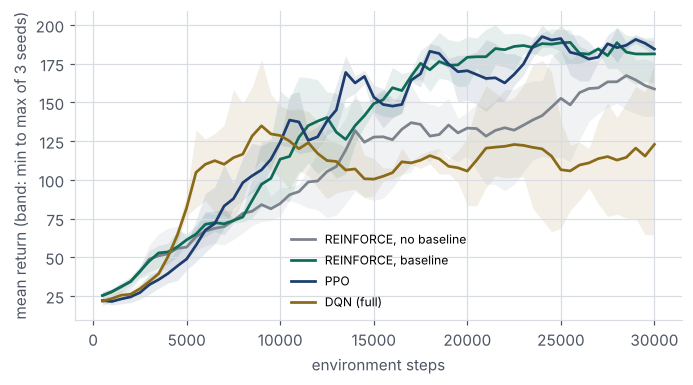

In [7]:
STEPS = 30000
agents = {
    "REINFORCE, no baseline": lambda s: smooth_curve(train_reinforce(s, STEPS, baseline=False), STEPS),
    "REINFORCE, baseline":    lambda s: smooth_curve(train_reinforce(s, STEPS, baseline=True), STEPS),
    "PPO":                    lambda s: smooth_curve(train_ppo(s, STEPS)[0], STEPS),
    "DQN (full)":             lambda s: smooth_curve(train_dqn(s, steps=STEPS), STEPS),
}
curves, secs = {}, {}
for name, fn in agents.items():
    t0 = time.time()
    curves[name] = np.array([fn(s) for s in range(3)])
    secs[name] = (time.time() - t0) / 3
print(f"{'agent':24s} {'last 5,000 steps, per seed':>28s} {'mean':>7s} {'whole-run mean':>15s} {'seconds per run':>16s}")
for name in agents:
    last = np.nanmean(curves[name][:, -10:], axis=1)
    print(f"{name:24s} {str(np.round(last, 0)):>28s} {last.mean():7.1f} {np.nanmean(curves[name]):15.1f} {secs[name]:16.0f}")
fig, ax = plt.subplots(figsize=(6.4, 3.6)); xs = np.arange(500, STEPS + 1, 500)
for (name, c), col in zip(curves.items(), [MUTED, GREEN, NAVY, AMBER]):
    ax.plot(xs, np.nanmean(c, 0), color=col, label=name, lw=1.8); ax.fill_between(xs, np.nanmin(c, 0), np.nanmax(c, 0), color=col, alpha=0.10, lw=0)
ax.set_xlabel("environment steps"); ax.set_ylabel("mean return (band: min to max of 3 seeds)"); ax.legend(fontsize=8, frameon=False)
plt.tight_layout(); plt.show()

On this task the policy-gradient agents reach a higher return than the DQN within the same number of environment steps, and they are cheaper per run. That is a statement about this task and this budget, not about the two families. CartPole has only two actions and a smooth, dense reward, which suits a policy that can simply tilt its probabilities;
DQN's strength is in tasks where reusing old experience matters more. The baseline version of REINFORCE ends higher than the version without one, and the gap is small relative to the spread between seeds, so with three seeds it is suggestive and not settled.

## 3. Why PPO clips

A policy gradient is valid only for the policy that collected the data. PPO reuses each batch for several passes, so after the first pass the data is slightly off-policy. The ratio $\rho = \pi_\theta(a \mid s) / \pi_{\text{old}}(a \mid s)$ measures how far the new policy has moved on a sample. The clipped objective for one sample with advantage $A$ is
$\min\left(\rho A,\ \text{clip}(\rho, 1 - \epsilon, 1 + \epsilon)\, A\right)$. We print it for a range of ratios, which shows its shape: when the action was good ($A > 0$), pushing its probability up earns no extra credit past $1 + \epsilon$; when it was bad ($A < 0$), pushing it down earns none below $1 - \epsilon$,
and a change in the harmful direction is never clipped.

ratio        [0.5 0.8 0.9 1.  1.1 1.2 1.5 2. ]
A = +1       [0.5 0.8 0.9 1.  1.1 1.2 1.2 1.2]
A = -1       [-0.8 -0.8 -0.9 -1.  -1.1 -1.2 -1.5 -2. ]
no clip A+1  [0.5 0.8 0.9 1.  1.1 1.2 1.5 2. ]


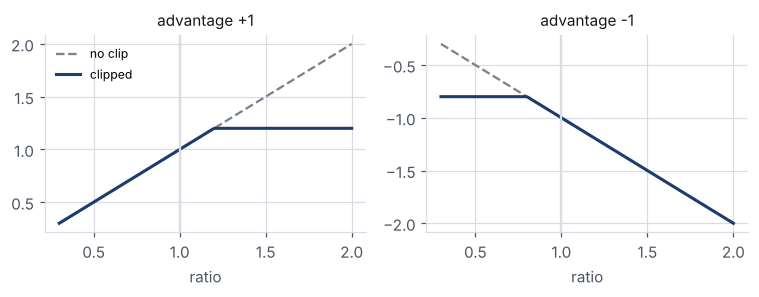

In [8]:
rho = torch.tensor([0.5, 0.8, 0.9, 1.0, 1.1, 1.2, 1.5, 2.0])
print("ratio       ", np.round(rho.numpy(), 2))
print("A = +1      ", np.round(ppo_clip_objective(rho, torch.ones(8), 0.2).numpy(), 2))
print("A = -1      ", np.round(ppo_clip_objective(rho, -torch.ones(8), 0.2).numpy(), 2))
print("no clip A+1 ", np.round(rho.numpy(), 2))
fig, ax = plt.subplots(1, 2, figsize=(7, 2.8), sharey=False)
r = torch.linspace(0.3, 2.0, 200)
for a_, A, t in zip(ax, (1.0, -1.0), ("advantage +1", "advantage -1")):
    a_.plot(r, r * A, color=MUTED, ls="--", label="no clip"); a_.plot(r, ppo_clip_objective(r, torch.full_like(r, A), 0.2), color=NAVY, lw=2, label="clipped")
    a_.axvline(1, color=RULE); a_.set_title(t, fontsize=10, color=INK); a_.set_xlabel("ratio")
ax[0].legend(frameon=False, fontsize=8); plt.tight_layout(); plt.show()

The clip only removes the incentive to move far in the direction that the advantage prefers; it does not stop the optimizer from moving. We test whether this matters in two settings, each with three seeds and the same 30,000 steps: the ordinary one used above (learning rate 3e-4, six passes), and an aggressive one (learning rate 3e-3, twenty passes over every batch) that takes large steps on stale data.
We also report the share of samples whose ratio left the $[0.8, 1.2]$ band, averaged over training.

In [9]:
settings = {
    "ordinary steps, clipped":   dict(),
    "ordinary steps, no clip":   dict(use_clip=False),
    "aggressive steps, clipped": dict(lr=3e-3, epochs=20),
    "aggressive steps, no clip": dict(lr=3e-3, epochs=20, use_clip=False),
}
print(f"{'setting':28s} {'last 5,000 steps, per seed':>28s} {'mean':>7s} {'worst point of curve':>22s} {'share outside the band':>24s}")
ppo_curves = {}
for name, kw in settings.items():
    cs, fr = [], []
    for s in range(3):
        log, stats = train_ppo(s, STEPS, **kw)
        cs.append(smooth_curve(log, STEPS)); fr.append(np.mean([x[1] for x in stats]))
    cs = np.array(cs); ppo_curves[name] = cs
    last = np.nanmean(cs[:, -10:], axis=1)
    print(f"{name:28s} {str(np.round(last, 0)):>28s} {last.mean():7.1f} {str(np.round(np.nanmin(cs, axis=1), 0)):>22s} {np.mean(fr):24.2f}")

setting                        last 5,000 steps, per seed    mean   worst point of curve   share outside the band


ordinary steps, clipped                  [188. 182. 183.]   184.4          [19. 23. 22.]                     0.03


ordinary steps, no clip                  [176. 198. 196.]   189.9          [19. 23. 22.]                     0.16


aggressive steps, clipped                [200. 200. 200.]   200.0          [19. 23. 22.]                     0.10


aggressive steps, no clip                   [ 9. 59.  9.]    25.9          [ 9. 23.  9.]                     0.22


With ordinary steps the clip makes no measurable difference: both versions learn and the gaps between them are inside the spread between seeds. With aggressive steps it makes all the difference. The clipped agent still reaches the maximum return of 200 on every seed, while the unclipped one ends at 9, 59 and 9, because a single over-large update on stale data wrecks the policy and the next batch is then collected by the wrecked policy. Without the clip, 22% of samples leave the band in the aggressive setting against 10% with it.
This is what PPO is for: it lets a batch be reused heavily, which makes it sample-efficient, without a trust-region computation. It is also why PPO is the default optimizer in large-scale post-training.

**Try it.** Change the clip range $\epsilon$ to 0.05 and to 0.5 under the aggressive setting. Then add an entropy bonus (`ent=0.01`) to REINFORCE-like training and see whether it changes how quickly the policy becomes deterministic.